# Exposure at Default for Revolving Credit: Credit Conversion Factors from Drawn and Undrawn Balances, Fractional Regression versus Gradient Boosting versus a Sequence Model on 100,000 Credit Cards

For a loan, exposure at default is roughly the outstanding balance. For a credit card or a credit line it is not: borrowers in trouble draw on their unused limits before they default, so the exposure at default (EAD) is usually larger than today's balance. Regulatory models express this with a **credit conversion factor** (CCF): the share of today's undrawn limit that will have been drawn by the time of default. The estimate needs defaulted accounts observed a fixed period before default, which makes the data scarce and noisy; observed CCFs are often negative (the borrower repaid) or above one (the limit was raised), and their distribution is U-shaped. This notebook builds 12-month CCFs from the monthly card histories in the Home Credit data, compares the statistical properties of the CCF with those of alternative EAD targets, and models the CCF with a regulatory-style lookup table, a fractional logit, LightGBM and a recurrent neural network that reads the account's 12 monthly statements before the reference date.

**What it does.**

1. It reads 3.8 million monthly statements of 104,000 credit cards, shows why the choice between technical and material delinquency decides whether there is any exposure to model, finds each card's first month more than 30 days past due on a material amount, and takes the reference date 12 months earlier (the fixed-horizon approach).
2. It computes the realised CCF, the loan-equivalent factor, the utilisation at default and the ratio of EAD to the limit, and shows how they are distributed.
3. It builds features from the account's limit, balance, payments, drawings and delinquency at and before the reference date, and from the customer's application.
4. It models the CCF with a lookup table by utilisation band, a fractional logit, LightGBM and a GRU sequence model, evaluated by repeated cross-validation, and reports the error on CCF and on EAD, and the bias of portfolio EAD.
5. It checks how the CCF depends on the horizon (3, 6 and 12 months before default) and compares modelled EAD with Basel's standardised 10% and 40% conversion factors.

**Data.** Home Credit Default Risk: monthly credit-card balances and application data (Kaggle; downloaded by hand into `data/home_credit/` at the repository root).

**Methods.** Fixed-horizon CCF estimation, the loan-equivalent approach, lookup tables, fractional logit regression, LightGBM, gated recurrent units in PyTorch, grouped repeated cross-validation, and portfolio EAD bias.

**Key output.** The distribution of realised CCFs, out-of-sample errors of each model on CCF and EAD, feature importance, CCF by horizon, and portfolio EAD under each approach.

## 1. Conversion factors in one page

For an account that defaults at time *t*_d, fix a reference date *t*_r = *t*_d − 12 months, with limit *L*, drawn balance *B* and undrawn amount *U* = *L* − *B*. The realised **credit conversion factor** is

CCF = (EAD − *B*) / (*L* − *B*),

so that EAD = *B* + CCF × *U*. The **loan-equivalent factor** (LEQ) is the same quantity under another name in the U.S. literature; the **EAD factor** is EAD / *L*.

**Why it is hard.**
- When *U* is small the ratio explodes, so accounts near their limit are excluded or capped.
- Realised CCFs pile up at 0 (no further drawing) and at 1 (full drawdown), with some below 0 (repayment) and above 1 (limit increases, fees and interest). Means are therefore unstable, and least squares is a poor fit; fractional regression or models of EAD directly (Tong et al., 2016; Leow & Crook, 2016) are common remedies.
- Regulators require the 12-month fixed horizon (or a cohort approach) and the CCF to be floored at zero in capital; Basel's standardised approach uses 10% for unconditionally cancellable retail commitments and 40% for other commitments (BCBS, 2017).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import statsmodels.api as sm
import torch
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2018
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
HORIZON = 12
# material days past due that define the delinquency event (see section 3)
DPD_EVENT = 30
# undrawn limit at the reference date must be at least 5% of the limit
MIN_UNDRAWN = 0.05
SEQ_LEN = 12
N_FOLDS, N_REPEATS = 5, 3

print(
    f"lightgbm {lgb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · torch 2.14.1+cu130 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. From monthly statements to realised conversion factors

Months are counted relative to the customer's current application (−1 is the most recent).

**Which default?** The data have two delinquency counters: days past due on any amount, and days past due ignoring small debts, the equivalent of the EBA's materiality threshold. The first produces 1,787 "defaults", but at the moment of default the median card owes almost nothing (a balance of about 0.2% of its limit): residual fees on cards the customer stopped using, *technical* defaults with no exposure to model. Only a few dozen cards reach 90 days past due on a material amount. The notebook therefore uses the first month a card is **more than 30 days past due on a material amount** as the event, which keeps several hundred accounts with real exposure; capital models would use 90 days, so the results describe the drawdown on the way to default.

The **reference date** is 12 months before the event. The card must have a statement then, be active, have no material arrears, and have at least 5% of its limit undrawn. EAD is the balance in the month of the event.

In [3]:
def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    raise FileNotFoundError(
        f"data/{name} not found: download the Home Credit files from Kaggle"
        " (see README)"
    )


HC = find_shared("home_credit")
CC = pd.read_csv(HC / "credit_card_balance.csv.zip")
APP = pd.read_csv(
    HC / "application_train.csv.zip",
    usecols=[
        "SK_ID_CURR",
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "DAYS_BIRTH",
        "DAYS_EMPLOYED",
        "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE",
        "CNT_CHILDREN",
        "REGION_RATING_CLIENT",
    ],
)
CC = CC.sort_values(["SK_ID_PREV", "MONTHS_BALANCE"]).reset_index(drop=True)
CC["util"] = CC["AMT_BALANCE"] / CC["AMT_CREDIT_LIMIT_ACTUAL"].replace(
    0, np.nan
)
CC["pay_ratio"] = (
    CC["AMT_PAYMENT_TOTAL_CURRENT"]
    / CC["AMT_INST_MIN_REGULARITY"].replace(0, np.nan)
).clip(0, 10)
CC["draw_ratio"] = (
    CC["AMT_DRAWINGS_CURRENT"]
    / CC["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
).clip(0, 2)
CC["atm_share"] = (
    CC["AMT_DRAWINGS_ATM_CURRENT"]
    / CC["AMT_DRAWINGS_CURRENT"].replace(0, np.nan)
).clip(0, 1)
CC["dpd30"] = (CC["SK_DPD"] > 30).astype(float)
DEFS = {
    "technical: any 90+ days past due": CC["SK_DPD"] > 90,
    "material: 90+ days past due on a non-trivial amount": (
        (CC["SK_DPD_DEF"] > 90) & (CC["AMT_BALANCE"] > 0)
    ),
    "material: 60+ days": (CC["SK_DPD_DEF"] > 60) & (CC["AMT_BALANCE"] > 0),
    "material: 30+ days (used here)": (
        (CC["SK_DPD_DEF"] > DPD_EVENT) & (CC["AMT_BALANCE"] > 0)
    ),
}
def_rows = {}
for k, cond in DEFS.items():
    t = CC[cond].groupby("SK_ID_PREV")["MONTHS_BALANCE"].min()
    at = CC.merge(t.rename("t"), left_on="SK_ID_PREV", right_index=True)
    at = at[at["MONTHS_BALANCE"] == at["t"]]
    def_rows[k] = {
        "cards": len(t),
        "median balance at event": at["AMT_BALANCE"].median(),
        "median balance / limit": at["util"].median(),
    }
DEF_T = pd.DataFrame(def_rows).T
first_def = (
    CC[DEFS["material: 30+ days (used here)"]]
    .groupby("SK_ID_PREV")["MONTHS_BALANCE"]
    .min()
    .rename("t_default")
)


def build_sample(h):
    d = first_def.to_frame()
    d["t_ref"] = d["t_default"] - h
    ref = CC.merge(
        d.reset_index(),
        left_on=["SK_ID_PREV", "MONTHS_BALANCE"],
        right_on=["SK_ID_PREV", "t_ref"],
    )
    at_def = CC.merge(
        d.reset_index(),
        left_on=["SK_ID_PREV", "MONTHS_BALANCE"],
        right_on=["SK_ID_PREV", "t_default"],
    )
    s = ref.set_index("SK_ID_PREV")[[
        "SK_ID_CURR",
        "t_ref",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
        "SK_DPD_DEF",
        "NAME_CONTRACT_STATUS",
    ]]
    s = s.rename(columns={"AMT_BALANCE": "B", "AMT_CREDIT_LIMIT_ACTUAL": "L"})
    s = s.join(
        at_def.set_index("SK_ID_PREV")[
            ["AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"]
        ].rename(
            columns={
                "AMT_BALANCE": "EAD",
                "AMT_CREDIT_LIMIT_ACTUAL": "L_default",
            }
        ),
        how="inner",
    )
    s = s[
        (s["NAME_CONTRACT_STATUS"] == "Active")
        & (s["SK_DPD_DEF"] == 0)
        & (s["L"] > 0)
        & ((s["L"] - s["B"]) >= MIN_UNDRAWN * s["L"])
    ]
    s["U"] = s["L"] - s["B"]
    s["CCF"] = (s["EAD"] - s["B"]) / s["U"]
    s["EAD/L"] = s["EAD"] / s["L"]
    s["util_ref"] = s["B"] / s["L"]
    return s


S = build_sample(HORIZON)
DIST = pd.Series({
    "cards with an event": len(first_def),
    "with a usable 12-month reference date": len(S),
    "CCF < 0": (S["CCF"] < 0).mean(),
    "CCF = 0 to 0.05": S["CCF"].between(0, 0.05).mean(),
    "CCF 0.95 to 1": S["CCF"].between(0.95, 1).mean(),
    "CCF > 1": (S["CCF"] > 1).mean(),
    "mean CCF": S["CCF"].mean(),
    "mean CCF floored at 0, capped at 1": S["CCF"].clip(0, 1).mean(),
    "median CCF": S["CCF"].median(),
    "limit changed by default": (S["L_default"] != S["L"]).mean(),
    "portfolio EAD / balance at reference": S["EAD"].sum() / S["B"].sum(),
    "portfolio realised CCF (Σ EAD − B) / Σ U": (
        (S["EAD"] - S["B"]).sum() / S["U"].sum()
    ),
})
print(f"{CC['SK_ID_PREV'].nunique():,} cards, {len(CC):,} monthly statements")
display(
    DEF_T.style.format({
        "cards": "{:,.0f}",
        "median balance at event": "{:,.0f}",
        "median balance / limit": "{:.3f}",
    }).set_caption(
        "Delinquency events under each definition: first month per card"
    )
)
DIST.to_frame("value").style.format(
    lambda v: f"{v:,.0f}" if v > 10 else f"{v:.3f}"
)

104,307 cards, 3,840,312 monthly statements


,cards,median balance at event,median balance / limit
technical: any 90+ days past due,"1,787",205,0.002
material: 90+ days past due on a non-trivial amount,27,"111,186",1.074
material: 60+ days,96,"102,256",1.058
material: 30+ days (used here),377,"102,517",1.033


,value
cards with an event,377
with a usable 12-month reference date,100
CCF < 0,0.370
CCF = 0 to 0.05,0.050
CCF 0.95 to 1,0.000
CCF > 1,0.420
mean CCF,0.200
"mean CCF floored at 0, capped at 1",0.515
median CCF,0.668
limit changed by default,0.020


## 4. Features at the reference date

All features use information up to the reference date only:
- **At the reference date:** utilisation, log limit, undrawn share, and the ratio of payment to the minimum instalment.
- **Over the previous 3 and 6 months:** the change in utilisation, average payment ratio, drawings as a share of the limit, the share of ATM drawings, the maximum days past due, and months on book.
- **From the application:** log income, log credit amount, age, years employed, number of children, regional rating, income type and education.

The **sequence model** reads the last 12 monthly statements up to the reference date (utilisation, payment ratio, drawings ratio, ATM share and a 30-days-past-due flag).

In [4]:
def window_stats(s):
    keys = s.reset_index()[["SK_ID_PREV", "t_ref"]]
    h = CC.merge(keys, on="SK_ID_PREV")
    h = h[
        (h["MONTHS_BALANCE"] <= h["t_ref"])
        & (h["MONTHS_BALANCE"] > h["t_ref"] - SEQ_LEN)
    ]
    f = {}
    for w in [3, 6]:
        hw = h[h["MONTHS_BALANCE"] > h["t_ref"] - w]
        g = hw.groupby("SK_ID_PREV")
        f[f"util change {w}m"] = g["util"].last() - g["util"].first()
        f[f"payment ratio {w}m"] = g["pay_ratio"].mean()
        f[f"drawings/limit {w}m"] = g["draw_ratio"].mean()
        f[f"ATM share {w}m"] = g["atm_share"].mean()
        f[f"max DPD {w}m"] = g["SK_DPD"].max()
    f["months on book"] = (
        CC[CC["SK_ID_PREV"].isin(s.index)]
        .groupby("SK_ID_PREV")["MONTHS_BALANCE"]
        .min()
        .reindex(s.index)
    )
    f["months on book"] = s["t_ref"] - f["months on book"]
    seq_cols = ["util", "pay_ratio", "draw_ratio", "atm_share", "dpd30"]
    h["k"] = h["MONTHS_BALANCE"] - h["t_ref"] + SEQ_LEN - 1
    seq = np.zeros((len(s), SEQ_LEN, len(seq_cols)), dtype=np.float32)
    pos = pd.Series(np.arange(len(s)), index=s.index)
    hh = h[h["SK_ID_PREV"].isin(pos.index)]
    seq[pos[hh["SK_ID_PREV"]].to_numpy(), hh["k"].astype(int).to_numpy()] = (
        hh[seq_cols].fillna(0).clip(-5, 10).to_numpy()
    )
    return pd.DataFrame(f).reindex(s.index), seq


F, SEQ = window_stats(S)
X = pd.DataFrame({
    "utilisation": S["util_ref"].clip(0, 1.5),
    "log limit": np.log(S["L"]),
    "undrawn share": S["U"] / S["L"],
}).join(F)
app = APP.set_index("SK_ID_CURR")
A = app.reindex(S["SK_ID_CURR"]).set_index(S.index)
X["log income"] = np.log(A["AMT_INCOME_TOTAL"].clip(lower=1))
X["log credit"] = np.log(A["AMT_CREDIT"].clip(lower=1))
X["age"] = -A["DAYS_BIRTH"] / 365.25
X["years employed"] = (
    -A["DAYS_EMPLOYED"].where(A["DAYS_EMPLOYED"] < 0) / 365.25
)
X["children"] = A["CNT_CHILDREN"]
X["region rating"] = A["REGION_RATING_CLIENT"]
for c in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]:
    X = X.join(
        pd.get_dummies(
            A[c], prefix=c.replace("NAME_", "").lower(), dtype=float
        )
    )
X = X.fillna(X.median(numeric_only=True)).fillna(0)
Y = S["CCF"].clip(0, 1)
GROUPS = S["SK_ID_CURR"].to_numpy()
print(
    f"{len(X):,} cards with an event and features; {X.shape[1]} features;"
    f" application data for {A['AMT_INCOME_TOTAL'].notna().mean():.0%}"
)
X.describe().T[["mean", "50%", "min", "max"]].head(12).style.format("{:.3f}")

100 cards with an event and features; 29 features; application data for 98%


,mean,50%,min,max
utilisation,0.580,0.692,0.000,0.950
log limit,11.778,11.813,10.714,13.710
undrawn share,0.420,0.308,0.050,1.000
util change 3m,-0.011,-0.038,-0.593,0.947
payment ratio 3m,1.427,1.004,0.000,6.667
drawings/limit 3m,0.050,0.000,0.000,0.625
ATM share 3m,0.980,1.000,0.000,1.000
max DPD 3m,1.150,0.000,0.000,93.000
util change 6m,-0.065,-0.094,-1.088,0.947
payment ratio 6m,1.404,1.129,1.000,7.500


## 5. Four models of the conversion factor

All models predict the CCF floored at 0 and capped at 1. They are compared in 5-fold cross-validation repeated three times, with folds grouped by customer:
- **Lookup table:** the mean CCF by utilisation band at the reference date (10 bands), the classic regulatory segmentation.
- **Fractional logit** on all features (Papke & Wooldridge, 1996).
- **LightGBM** with a cross-entropy objective.
- **GRU:** a gated recurrent unit (Cho et al., 2014) reading the 12-month sequence, concatenated with the static features, and a sigmoid output trained on binary cross-entropy against the fractional target.

**Metrics:**
- the mean absolute error on CCF;
- the mean absolute error on EAD relative to the limit;
- the **portfolio EAD bias**: predicted over actual total EAD, minus one.

In [5]:
class GRUNet(torch.nn.Module):
    def __init__(self, n_seq, n_static, h=32):
        super().__init__()
        self.gru = torch.nn.GRU(n_seq, h, batch_first=True)
        self.head = torch.nn.Sequential(
            torch.nn.Linear(h + n_static, 32),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(32, 1),
        )

    def forward(self, seq, stat):
        _, hN = self.gru(seq)
        return self.head(torch.cat([hN[-1], stat], 1)).squeeze(-1)


def fit_gru(seq, xs, y, epochs=60):
    mu, sd = xs.mean(0), xs.std(0) + 1e-6
    net = GRUNet(seq.shape[2], xs.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=2e-3, weight_decay=1e-4)
    S_t, X_t, Y_t = (
        torch.tensor(seq),
        torch.tensor((xs - mu) / sd, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32),
    )
    n = len(Y_t)
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(n)
        for i in range(0, n, 256):
            b = perm[i : i + 256]
            loss = torch.nn.functional.binary_cross_entropy_with_logits(
                net(S_t[b], X_t[b]), Y_t[b]
            )
            opt.zero_grad()
            loss.backward()
            opt.step()
    net.eval()
    return (
        lambda sq, x: torch.sigmoid(
            net(
                torch.tensor(sq),
                torch.tensor((x - mu) / sd, dtype=torch.float32),
            )
        )
        .detach()
        .numpy()
    )


def lookup_fit(xtr, ytr):
    edges = np.quantile(xtr["utilisation"], np.linspace(0, 1, 11))
    edges[0], edges[-1] = -np.inf, np.inf
    tab = ytr.groupby(pd.cut(xtr["utilisation"], edges, labels=False)).mean()
    return (
        lambda x: pd.cut(x["utilisation"], edges, labels=False)
        .map(tab)
        .fillna(ytr.mean())
        .to_numpy()
    )


def logit_fit(xtr, ytr):
    keep = xtr.columns[xtr.std() > 0]
    mu, sd = xtr[keep].mean(), xtr[keep].std()
    m = sm.GLM(
        ytr,
        sm.add_constant((xtr[keep] - mu) / sd),
        family=sm.families.Binomial(),
    ).fit()
    return lambda x: np.asarray(
        m.predict(sm.add_constant((x[keep] - mu) / sd, has_constant="add"))
    )


def gbm_fit(xtr, ytr):
    m = lgb.LGBMRegressor(
        objective="cross_entropy",
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=7,
        min_child_samples=10,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
        importance_type="gain",
    )
    m.fit(xtr, ytr)
    gbm_fit.last = m
    return lambda x: m.predict(x)


PRED = {
    k: np.zeros((N_REPEATS, len(X)))
    for k in ["lookup table", "fractional logit", "LightGBM", "GRU"]
}
imps = []
for rep in range(N_REPEATS):
    perm_groups = (
        pd.Series(GROUPS)
        .map(
            dict(
                zip(np.unique(GROUPS), rng.permutation(len(np.unique(GROUPS))))
            )
        )
        .to_numpy()
    )
    for tr, te in GroupKFold(N_FOLDS).split(X, Y, perm_groups):
        xtr, xte, ytr = X.iloc[tr], X.iloc[te], Y.iloc[tr]
        PRED["lookup table"][rep, te] = lookup_fit(xtr, ytr)(xte)
        PRED["fractional logit"][rep, te] = logit_fit(xtr, ytr)(xte)
        PRED["LightGBM"][rep, te] = gbm_fit(xtr, ytr)(xte)
        imps.append(
            pd.Series(gbm_fit.last.feature_importances_, index=X.columns)
        )
        PRED["GRU"][rep, te] = fit_gru(
            SEQ[tr], X.iloc[tr].to_numpy(np.float32), ytr.to_numpy()
        )(SEQ[te], X.iloc[te].to_numpy(np.float32))
PRED["constant (mean CCF)"] = np.tile(Y.mean(), (N_REPEATS, len(X)))
B_, U_, L_, EAD_ = (
    S["B"].to_numpy(),
    S["U"].to_numpy(),
    S["L"].to_numpy(),
    S["EAD"].to_numpy(),
)
rows = {}
for k, P in PRED.items():
    ead_hat = B_ + P * U_
    rows[k] = {
        "MAE, CCF": np.mean(np.abs(P - Y.to_numpy())),
        "MAE std across repeats": np.std(np.abs(P - Y.to_numpy()).mean(1)),
        "MAE, EAD / limit": np.mean(np.abs(ead_hat - EAD_) / L_),
        "portfolio EAD bias": np.mean(ead_hat.sum(1) / EAD_.sum() - 1),
        "correlation with realised CCF": np.mean(
            [np.corrcoef(p, Y)[0, 1] if np.std(p) > 0 else np.nan for p in P]
        ),
    }
for name, ccf in [
    ("Basel SA 10% (cancellable retail)", 0.10),
    ("Basel SA 40% (other commitments)", 0.40),
]:
    ead_hat = B_ + ccf * U_
    rows[name] = {
        "MAE, CCF": np.mean(np.abs(ccf - Y)),
        "MAE, EAD / limit": np.mean(np.abs(ead_hat - EAD_) / L_),
        "portfolio EAD bias": ead_hat.sum() / EAD_.sum() - 1,
        "correlation with realised CCF": np.nan,
    }
MODELS = pd.DataFrame(rows).T.sort_values("MAE, CCF")
IMP = pd.concat(imps, axis=1).mean(1)
IMP = (IMP / max(IMP.sum(), 1e-12)).sort_values(ascending=False)
display(
    MODELS.style.format(
        {
            "MAE, CCF": "{:.4f}",
            "MAE std across repeats": "{:.4f}",
            "MAE, EAD / limit": "{:.4f}",
            "portfolio EAD bias": "{:+.1%}",
            "correlation with realised CCF": "{:.3f}",
        },
        na_rep="",
    )
)
IMP.head(10).to_frame("LightGBM gain share").style.format("{:.1%}")

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


... (8 outputs left out)

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


/tmp/ipykernel_4000/2035365763.py:152: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  IMP = pd.concat(imps, axis=1).mean(1)


,"MAE, CCF",MAE std across repeats,"MAE, EAD / limit",portfolio EAD bias,correlation with realised CCF
GRU,0.3625,0.0130,0.2774,+0.7%,0.413
LightGBM,0.3692,0.0104,0.2860,-0.0%,0.354
constant (mean CCF),0.4539,0.0000,0.3127,-4.3%,
Basel SA 40% (other commitments),0.4623,,0.3196,-10.5%,
lookup table,0.4639,0.0074,0.3157,-2.9%,-0.029
fractional logit,0.4778,0.0285,0.3210,-0.9%,0.049
Basel SA 10% (cancellable retail),0.4981,,0.3465,-26.5%,


,LightGBM gain share
drawings/limit 6m,12.2%
months on book,11.2%
log credit,9.7%
util change 6m,9.4%
age,9.3%
utilisation,6.5%
util change 3m,6.2%
payment ratio 6m,6.1%
log income,4.7%
undrawn share,4.2%


## 6. Conversion factors by utilisation and by horizon

The table shows the realised CCF by utilisation band at the reference date. It also shows how the average CCF changes when the reference date is 3, 6 or 12 months before default: the closer to default, the more of the limit has already been drawn and the smaller the remaining conversion.

In [6]:
bands = pd.cut(
    S["util_ref"],
    [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95],
    labels=["0–10%", "10–30%", "30–50%", "50–70%", "70–90%", "90–95%"],
)
BY_UTIL = pd.DataFrame({
    "cards": S.groupby(bands, observed=True).size(),
    "mean CCF (raw)": S.groupby(bands, observed=True)["CCF"].mean(),
    "mean CCF (0–1)": Y.groupby(bands, observed=True).mean(),
    "share CCF ≥ 0.95": (
        (S["CCF"] >= 0.95).groupby(bands, observed=True).mean()
    ),
    "mean EAD / limit": S.groupby(bands, observed=True)["EAD/L"].mean(),
})
HZ = {}
for h in [3, 6, 12]:
    s = build_sample(h)
    HZ[f"{h} months"] = {
        "cards": len(s),
        "mean CCF (0–1)": s["CCF"].clip(0, 1).mean(),
        "median CCF": s["CCF"].median(),
        "mean utilisation at reference": s["util_ref"].mean(),
        "mean EAD / limit": s["EAD/L"].mean(),
    }
HZ = pd.DataFrame(HZ).T
display(
    BY_UTIL.style.format({
        "cards": "{:,.0f}",
        "mean CCF (raw)": "{:.3f}",
        "mean CCF (0–1)": "{:.3f}",
        "share CCF ≥ 0.95": "{:.1%}",
        "mean EAD / limit": "{:.3f}",
    })
)
HZ.style.format({
    "cards": "{:,.0f}",
    "mean CCF (0–1)": "{:.3f}",
    "median CCF": "{:.3f}",
    "mean utilisation at reference": "{:.3f}",
    "mean EAD / limit": "{:.3f}",
})

,cards,mean CCF (raw),mean CCF (0–1),share CCF ≥ 0.95,mean EAD / limit
util_ref,,,,,
0–10%,16,0.633,0.598,56.2%,0.633
10–30%,3,0.221,0.333,33.3%,0.383
30–50%,16,0.481,0.602,43.8%,0.707
50–70%,18,0.418,0.580,44.4%,0.799
70–90%,36,-0.020,0.427,36.1%,0.839
90–95%,11,-0.483,0.501,36.4%,0.886


,cards,mean CCF (0–1),median CCF,mean utilisation at reference,mean EAD / limit
3 months,114,0.452,0.275,0.518,0.720
6 months,133,0.491,0.536,0.544,0.743
12 months,100,0.515,0.668,0.580,0.769


## 7. Charts and dashboard

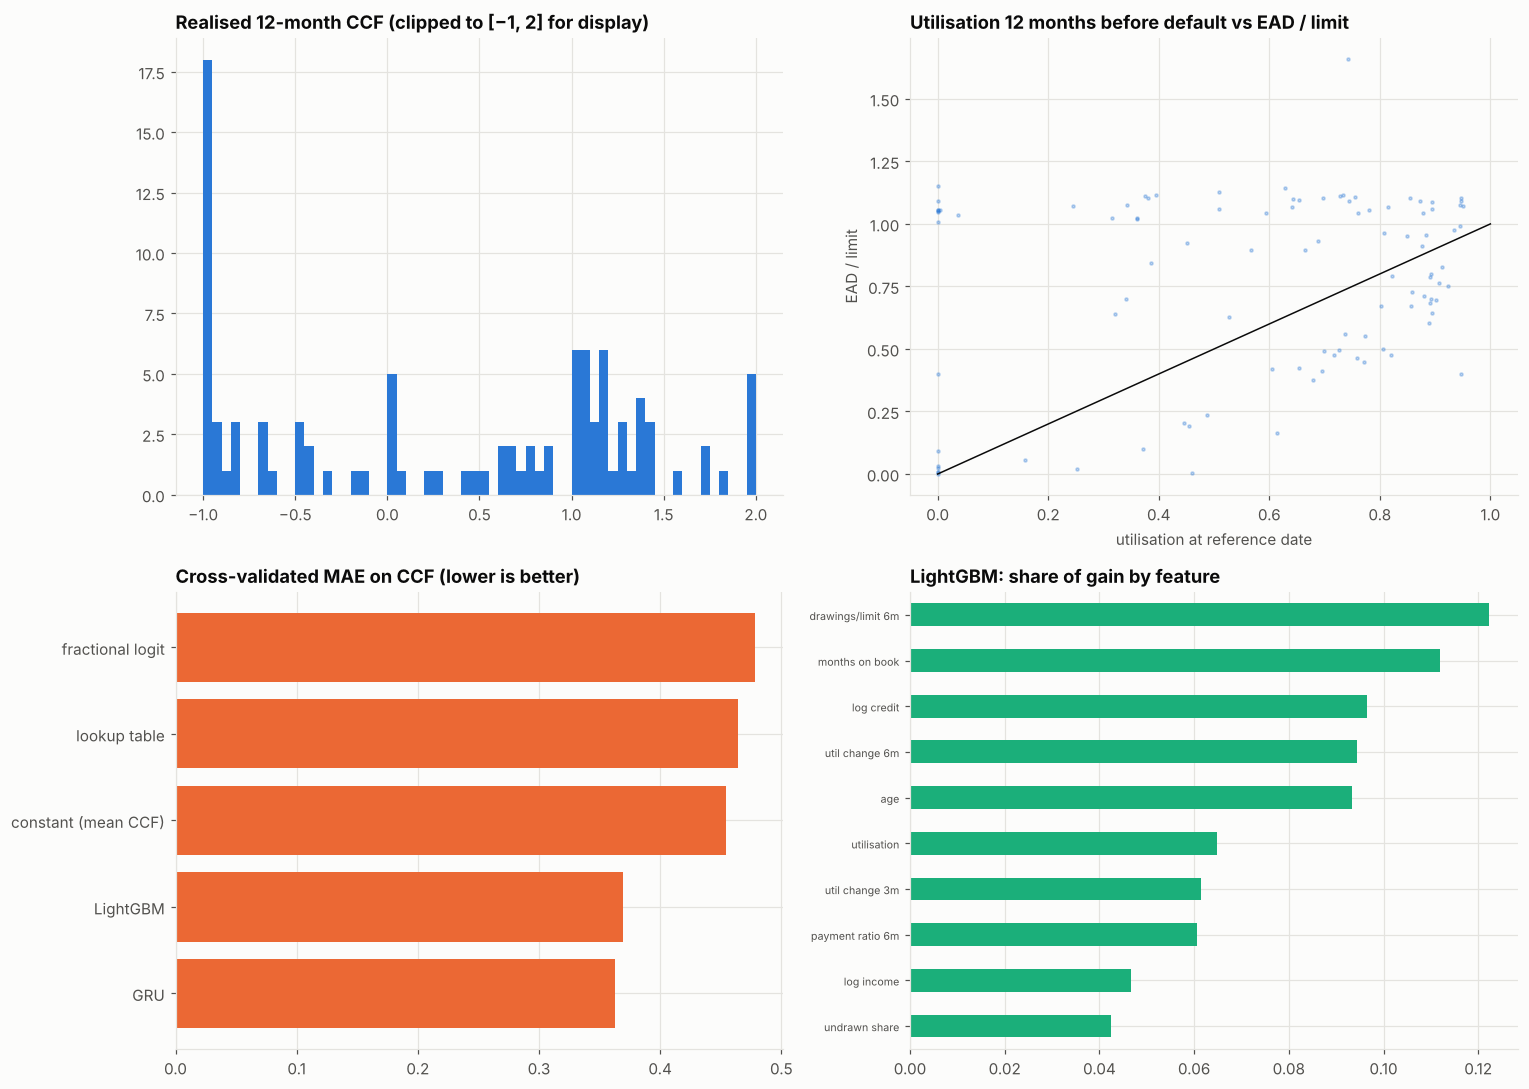

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
a.hist(S["CCF"].clip(-1, 2), bins=60, color=PALETTE[0])
a.set_title("Realised 12-month CCF (clipped to [−1, 2] for display)")
a = ax[0, 1]
a.scatter(
    S["util_ref"], S["EAD/L"].clip(0, 2), s=4, alpha=0.3, color=PALETTE[0]
)
a.plot([0, 1], [0, 1], color=INK, lw=1)
a.set_xlabel("utilisation at reference date")
a.set_ylabel("EAD / limit")
a.set_title("Utilisation 12 months before default vs EAD / limit")
a = ax[1, 0]
m_ = MODELS.drop(index=[i for i in MODELS.index if i.startswith("Basel")])
a.barh(m_.index, m_["MAE, CCF"], color=PALETTE[1])
a.set_title("Cross-validated MAE on CCF (lower is better)")
a = ax[1, 1]
IMP.head(10).sort_values().plot.barh(ax=a, color=PALETTE[2])
a.set_title("LightGBM: share of gain by feature")
a.tick_params(axis="y", labelsize=7)
fig.tight_layout()
save_fig(fig, "01_ead_ccf")
plt.show()

In [8]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Mean CCF by utilisation band",
        "Portfolio EAD bias by approach (%)",
    ),
)
dash.add_trace(
    go.Bar(
        x=BY_UTIL.index.astype(str),
        y=BY_UTIL["mean CCF (0–1)"],
        name="mean CCF (0–1)",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=BY_UTIL.index.astype(str),
        y=BY_UTIL["share CCF ≥ 0.95"],
        name="share CCF ≥ 0.95",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=MODELS.index, y=MODELS["portfolio EAD bias"] * 100, name="EAD bias"
    ),
    1,
    2,
)
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Exposure at default for revolving credit: realised CCFs and model"
        " comparison"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The definition of default decides whether there is anything to model.**

| Event definition | Cards | Median balance at event | Median balance / limit |
|---|---|---|---|
| Any 90+ days past due ("technical") | 1,787 | 205 | 0.2% |
| 90+ days past due on a material amount | 27 | 111,186 | 107% |
| 60+ days, material | 96 | 102,256 | 106% |
| 30+ days, material (used here) | 377 | 102,517 | 103% |

Counting days past due on any amount produces 1,787 "defaults", but almost all are residual fees on cards the customer had stopped using, with no exposure at all. Applying a materiality threshold, as the EBA requires, leaves 27 true 90-day defaults, too few to model, and 377 cards that went more than 30 days past due on a material amount. At that point they owe, at the median, slightly *more* than their limit (103%), because interest and fees are added on top of a fully drawn line. Of the 377, 100 had a usable statement 12 months earlier: active, current, and with at least 5% of the limit undrawn.

**Realised CCFs are U-shaped and unstable.**
- **Distribution:** 37% of the 100 cards had a negative CCF (they repaid part of their balance over the year) and 42% a CCF above one (they ended above their limit). Only 21% fell in between.
- **Summary statistics:** the mean raw CCF is 0.20, the mean after flooring at 0 and capping at 1 is 0.52, and the median 0.67.
- **Portfolio level:** total EAD was 1.47 times the total balance 12 months earlier, and borrowers drew 60% of the undrawn amount.
- **By utilisation:** accounts with little drawn 12 months before (0–10% utilisation) ended at 63% of their limit on average; those already above 90% ended at 89%.

**Horizon.** The closer the reference date is to the event, the more has already been drawn:
- the mean utilisation at the reference date rises from 52% (3 months before) to 58% (12 months), on samples that differ in composition;
- the mean capped CCF is 0.45, 0.49 and 0.52 at 3, 6 and 12 months;
- the median CCF is 0.27, 0.54 and 0.67.

The 12-month fixed horizon required for capital captures most of the drawdown.

**Models.** Cross-validated on 100 cards (5 folds × 3 repeats):

| Approach | MAE on CCF | MAE on EAD / limit | Portfolio EAD bias |
|---|---|---|---|
| GRU on 12 monthly statements + static features | 0.363 | 0.277 | +0.7% |
| LightGBM | 0.369 | 0.286 | −0.0% |
| Constant (mean CCF) | 0.454 | 0.313 | −4.3% |
| Basel standardised 40% | 0.462 | 0.320 | −10.5% |
| Lookup table by utilisation band | 0.464 | 0.316 | −2.9% |
| Fractional logit | 0.478 | 0.321 | −1.0% |
| Basel standardised 10% | 0.498 | 0.347 | −26.5% |

- **Machine-learning models:** the GRU and LightGBM cut the error by about a fifth relative to a constant (repeat-to-repeat variation 0.01), and their predictions correlate 0.35–0.41 with realised CCFs.
- **Most informative features:** drawings relative to the limit over the last six months, months on book, the customer's credit amount and age, and recent changes in utilisation. Borrowers already drawing heavily, and newer accounts, convert more.
- **Lookup table and fractional logit:** neither beat the constant on 100 observations.
- **Basel's standardised factors:** both understate EAD, by 27% (10% CCF) and 10% (40% CCF), because these borrowers drew 60% of their headroom.

**What this means for EAD modelling.**
- **Materiality threshold:** apply it before counting defaults. Without it, revolving portfolios are flooded with technical defaults that have zero exposure, and every EAD statistic is meaningless.
- **Floors and caps:** realised CCFs need floors and caps, or a model of EAD over the limit, to be usable. Report the raw distribution so that the effect of the truncation is visible.
- **Small samples:** with a hundred observations, behavioural trajectories (drawdown over the last months) carry most of the signal. A sequence model or gradient boosting can use them, but the gain must be judged against fold-to-fold noise, and a simple, conservative segmentation remains defensible for capital.
- **Standardised CCFs** for unconditionally cancellable retail lines (10%) can be far too low for borrowers heading into delinquency; IRB estimates should be checked against them in both directions.

**Limitations.**
- **Data:** a single lender's card book; months are relative to each customer's later application, not calendar time, so no economic cycle can be identified. The event is 30 days past due on a material amount, not the 90-day regulatory default.
- **Sample:** 100 accounts with a valid 12-month reference date; all model comparisons are subject to large sampling error. The application data are those of a later loan application, joined by customer.
- **Targets:** CCFs are capped to [0, 1] for modelling, while 42% of realised CCFs exceed one; a model of EAD relative to the limit would capture the over-limit amounts.

In [9]:
DIST.to_csv(OUT_DIR / "ccf_distribution_summary.csv")
DEF_T.to_csv(OUT_DIR / "default_definitions.csv")
MODELS.to_csv(OUT_DIR / "model_comparison.csv")
IMP.to_csv(OUT_DIR / "lightgbm_feature_importance.csv")
BY_UTIL.to_csv(OUT_DIR / "ccf_by_utilisation.csv")
HZ.to_csv(OUT_DIR / "ccf_by_horizon.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_ead_ccf.png, ccf_by_horizon.csv, ccf_by_utilisation.csv, ccf_distribution_summary.csv, dashboard.html, dashboard.png, default_definitions.csv, lightgbm_feature_importance.csv, model_comparison.csv


## References

### Exposure at default

- Basel Committee on Banking Supervision. (2017). *Basel III: Finalising post-crisis reforms*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d424.htm
- Tong, E. N. C., Mues, C., Brown, I., & Thomas, L. C. (2016). Exposure at default models with and without the credit conversion factor. *European Journal of Operational Research, 252*(3), 910–920. https://doi.org/10.1016/j.ejor.2016.01.054
- Leow, M., & Crook, J. (2016). A new mixture model for the estimation of credit card exposure at default. *European Journal of Operational Research, 249*(2), 487–497. https://doi.org/10.1016/j.ejor.2015.10.001

### Methods

- Papke, L. E., & Wooldridge, J. M. (1996). Econometric methods for fractional response variables with an application to 401(k) plan participation rates. *Journal of Applied Econometrics, 11*(6), 619–632. https://doi.org/10.1002/(SICI)1099-1255(199611)11:6<619::AID-JAE418>3.0.CO;2-1
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. In *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734). https://doi.org/10.3115/v1/D14-1179
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

### Data

- Home Credit Group. (2018). *Home Credit Default Risk* [Data set]. Kaggle. https://www.kaggle.com/competitions/home-credit-default-risk/data